# Лабораторная работа 3. Кластеризация методом DBSCAN

*Студентка:* Барашкова Альбина Станиславовна <br>
*Цель:* Сегментировать потребителей леденцов на основе мотивов их потребления с помощью кластеризации методом DBSCAN для последующего формирования маркетинговых стратегий.<br>
*Гипотеза:* Потребительская аудитория неоднородна и разделяется на 3-4 устойчивых сегмента <br>

In [44]:
import numpy as np
import pandas as pd
import seaborn as sns

import matplotlib
import matplotlib.pyplot as plt
matplotlib.style.use('ggplot')
%matplotlib inline

from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score)
from sklearn.cluster import DBSCAN, KMeans
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import linkage, fcluster


In [45]:
import warnings
from sklearn.exceptions import ConvergenceWarning

# Отключаем UserWarning от sklearn
warnings.filterwarnings('ignore', category=UserWarning, module='sklearn')

In [46]:
df = pd.read_csv('Леденцы.dat', sep =';')
df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


In [47]:
df.shape

(338, 11)

In [48]:
df = df.reset_index(drop = True)

Все признаки V1–V11 находятся на сопоставимых шкалах  (баллы от 1 до 5), и ни один из них не имеет существенно большего числового масштаба, чем остальные, поэтому стандартизация не нужна.<br>
Пропусков и выбросов нет <br>

In [49]:
df.describe()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
count,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000
mean,3.544379,3.526627,3.517751,3.411243,3.207101,3.204142,3.254438,3.289941,3.603550,3.550296,3.565089
std,0.955748,0.956410,0.990150,0.992311,0.867314,0.869725,0.844107,0.821784,0.969682,0.927082,0.942042
min,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
25%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
50%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
75%,5.000000,5.000000,5.000000,4.000000,3.000000,3.000000,3.000000,3.000000,5.000000,5.000000,5.000000
max,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


In [50]:
feature_cols = ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11']
X = df[feature_cols].values

### Выбор параметров

В академической литературе базовое правило для min_samples — это D+1, где D — количество признаков. <br>
У нас 11 признаков (V1−V11). Значит, минимальный порог — 12. <br>
Учитывая, что в предыдущих лабах самый маленький кластер состоял из ~59 человек, логично взять min_samples = 15, 20 или 30. Попробуем несколько вариантов<br>

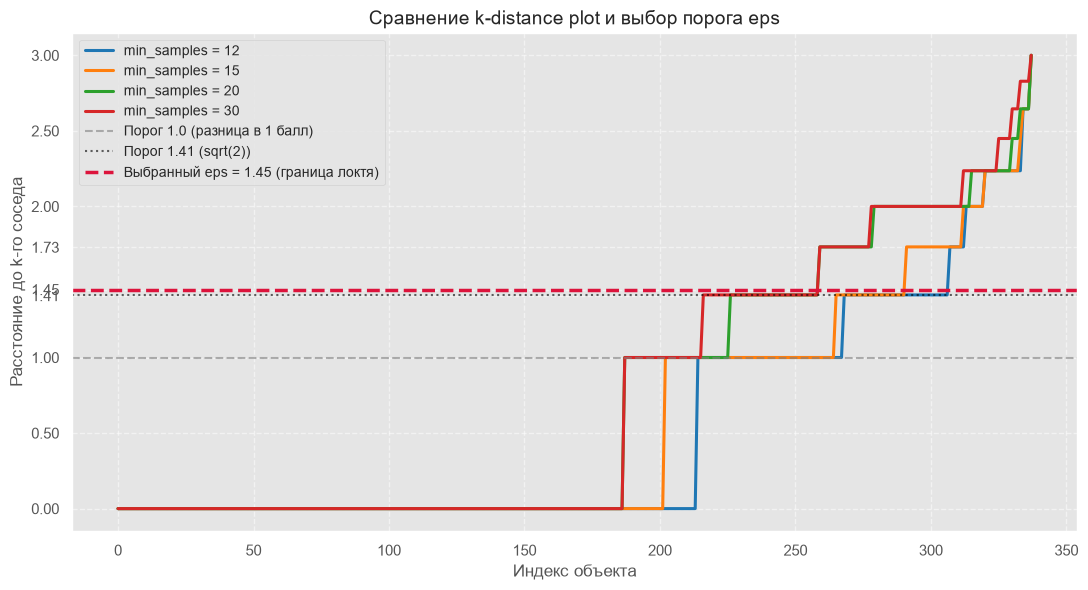

In [51]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.neighbors import NearestNeighbors

min_samples_list = [12, 15, 20, 30]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

plt.figure(figsize=(11, 6))

for ms, col in zip(min_samples_list, colors):
    # Обучаем k-NN для текущего min_samples
    nn = NearestNeighbors(n_neighbors=ms)
    nn.fit(X)
    distances, _ = nn.kneighbors(X)

    # Берем расстояние до самого дальнего (ms-го) соседа
    k_dist = distances[:, -1]

    # Сортируем по возрастанию
    k_dist_sorted = np.sort(k_dist)

    plt.plot(
        k_dist_sorted,
        label=f'min_samples = {ms}',
        color=col,
        linewidth=2.2,
    )

# Теоретические ступеньки шкалы Лайкерта (вспомогательные линии)
plt.axhline(
    y=1.0,
    color='gray',
    linestyle='--',
    alpha=0.6,
    label='Порог 1.0 (разница в 1 балл)',
)
plt.axhline(
    y=1.414,
    color='black',
    linestyle=':',
    alpha=0.6,
    label='Порог 1.41 (sqrt(2))',
)

# --- ФИНАЛЬНЫЙ ВЫБРАННЫЙ ПОРОГ EPS = 1.45 ---
plt.axhline(
    y=1.45,
    color='crimson',
    linestyle='--',
    linewidth=2.5,
    label='Выбранный eps = 1.45 (граница локтя)',
)

plt.title('Сравнение k-distance plot и выбор порога eps', fontsize=14)
plt.xlabel('Индекс объекта', fontsize=12)
plt.ylabel('Расстояние до k-го соседа', fontsize=12)

# Добавляем 1.45 в метки по оси Y, чтобы было видно точное значение
plt.yticks([0, 0.5, 1.0, 1.41, 1.45, 1.73, 2.0, 2.5, 3.0])

plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=10, loc='upper left')
plt.tight_layout()
plt.show()

#### Обоснование выбора min_samples = 15 на основе графика <br>
Анализ графика (поведение линий): <br>
Линии 12 (синяя) и 15 (оранжевая) идут практически синхронно. Это означает, что при переходе от 12 к 15 соседям плотность ядер сохраняется — мы получаем устойчивое решение, не теряя данные. <br>

Линии 20 (зеленая) и 30 (красная) отсекают данные слишком агрессивно: зеленая линия делает резкий скачок к уровню 1.41 уже на 225-м объекте. Учитывая, что наши наименьшие сегменты насчитывают всего по 59–61 человеку, требовать 20 (и тем более 30) соседей в узком радиусе — избыточно жестко, это выбросит в шум треть нормальной аудитории. <br>

Итог выбора: Выбираем min_samples = 15 как идеальный баланс: он строже минимального порога 12 (защита от случайных микро-выбросов), но мягче 20 (не разрушает малые сегменты). <br>

#### Обоснование выбора eps по min_samples = 15 на основе графика <br>

Зона максимальной плотности: От 0 до ~200 объекта расстояние равно 0 (люди с абсолютно идентичными ответами).  <br>

Зона ядра кластеров: От ~200 до 265 объекта расстояние держится на уровне 1.0 (разница всего в 1 балл по одному вопросу).  <br>

Зона перехода (граница сегментов): От 265 до 305 объекта расстояние равно sqrt(2) ≈1.41 (разница в 1 балл по двум вопросам). Это всё еще компактные группы.  <br>

Точка перегиба: Ровно на 305-м объекте прямой отрезок 1.41 заканчивается, и график делает резкий скачок вверх — на 1.73, 2.0 и далее крутой лестницей до 3.0.
Все объекты правее 305-й точки (около 30 человек) находятся на большом удалении от плотных ядер — это разреженное пространство, аномалии и противоречивые ответы. <br> 

Выбор eps = 1.45 (или 1.42): Мы берем значение чуть выше отрезка на 1.41, чтобы включить всех людей из плотных ядер (компенсируя погрешность округления чисел с плавающей точкой), а резкий скачок после 305-го объекта отсечь в шум. <br>

Почему не eps = 1.0 (или 1.1): Если бы мы провели срез на 1.1, мы бы потеряли отрезок между 265 и 305 объектами. В шум улетели бы ~70 человек (более 20% выборки), что неоправданно много для плотных данных.  <br>

Почему не eps > 1.7: Захватит крутой подъем, из-за чего шум склеит разные кластеры между собой.  <br>

### Перебор по сетке

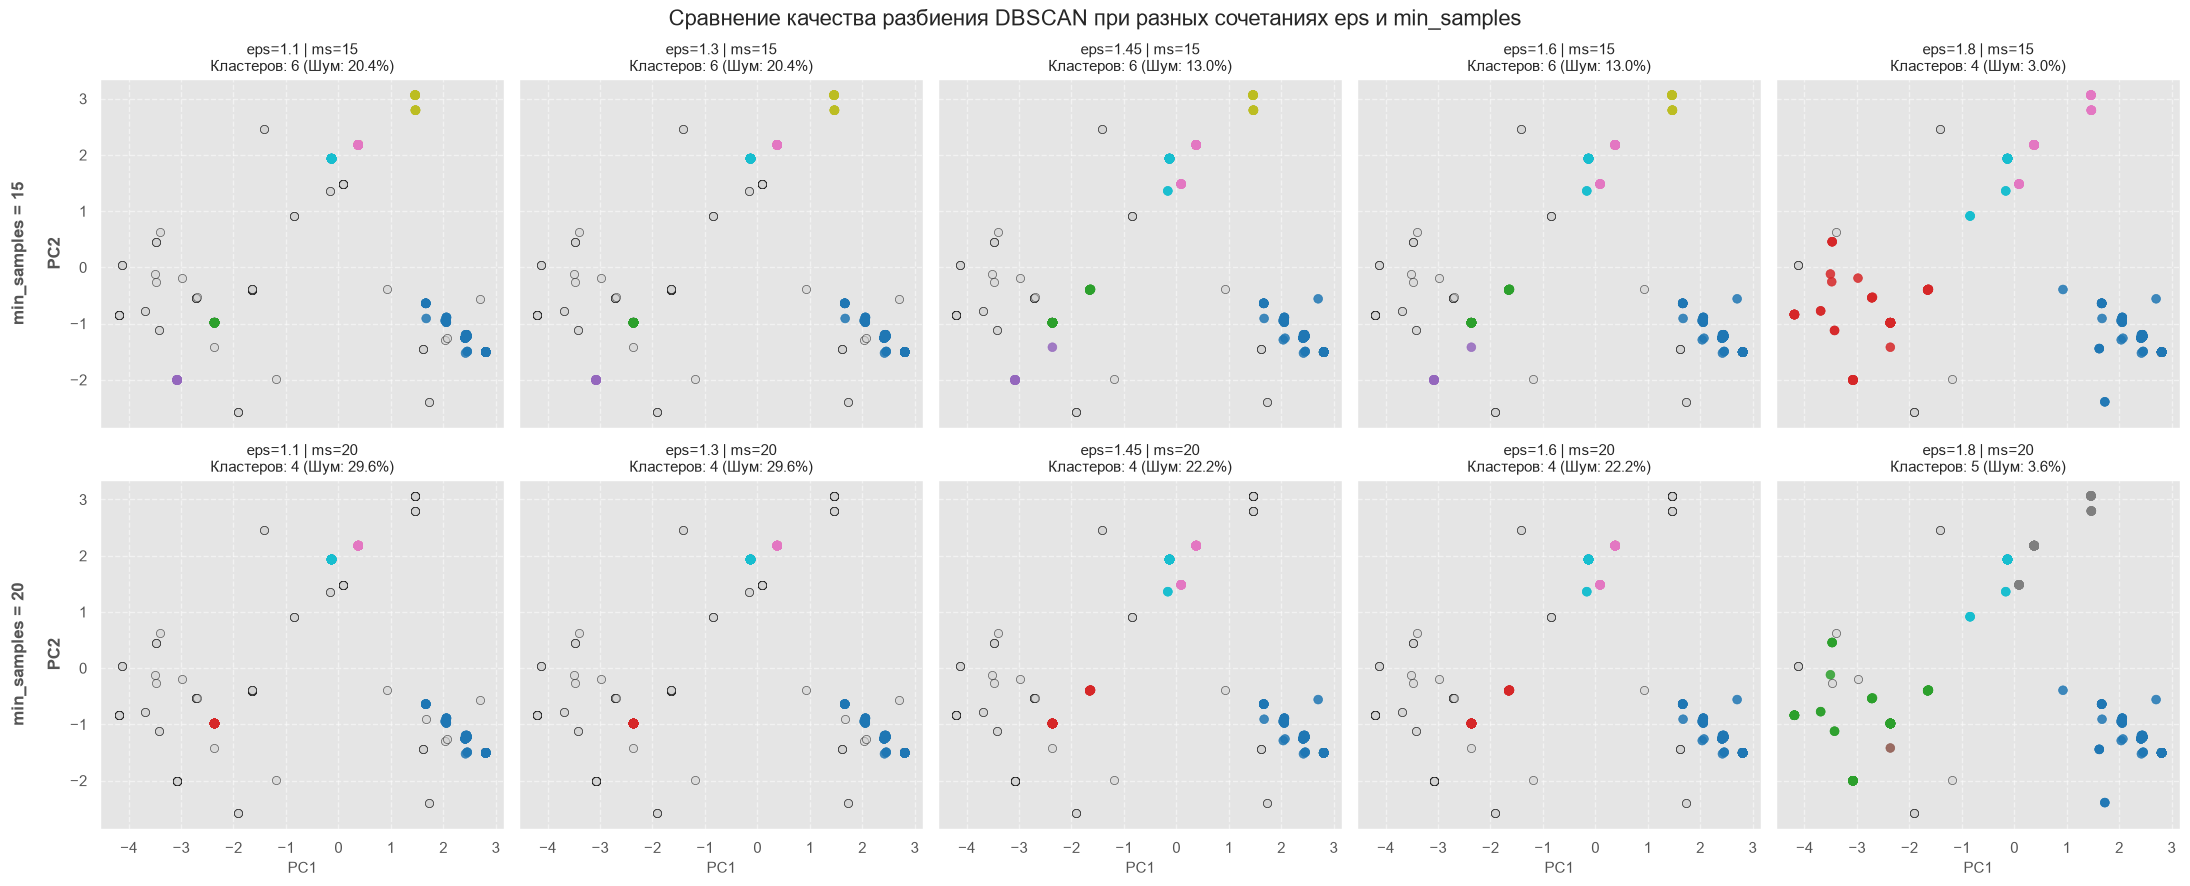

,min_samples,eps,Кол-во кластеров,Доля шума (%),Кол-во шума (чел),Silhouette (без шума)
0,15,1.100000,6,20.410000,69,0.905000
1,15,1.300000,6,20.410000,69,0.905000
2,15,1.450000,6,13.020000,44,0.825000
3,15,1.600000,6,13.020000,44,0.825000
4,15,1.800000,4,2.960000,10,0.745000
5,20,1.100000,4,29.590000,100,0.911000
6,20,1.300000,4,29.590000,100,0.911000
7,20,1.450000,4,22.190000,75,0.854000
8,20,1.600000,4,22.190000,75,0.854000
9,20,1.800000,5,3.550000,12,0.638000


In [52]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# Сжимаем признаки через PCA в 2D для визуализации
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

# Сетка параметров для проверки
eps_values = [1.1, 1.3, 1.45, 1.6, 1.8]
min_samples_list = [15, 20]

# Создаем сетку графиков: 2 строки (для ms=15 и ms=20), 5 колонок (под каждый eps)
fig, axes = plt.subplots(
    len(min_samples_list),
    len(eps_values),
    figsize=(22, 9),
    sharex=True,
    sharey=True,
)

summary = []

for row_idx, ms in enumerate(min_samples_list):
    for col_idx, eps in enumerate(eps_values):
        ax = axes[row_idx, col_idx]

        # Обучаем DBSCAN
        db = DBSCAN(eps=eps, min_samples=ms)
        labels = db.fit_predict(X)

        # Анализ кластеров и шума
        core_mask = labels != -1
        unique_clusters = set(labels[core_mask])
        n_clusters = len(unique_clusters)
        n_noise = np.sum(labels == -1)
        noise_fraction = np.mean(labels == -1)

        # Расчет силуэта (только для объектов в кластерах, без шума)
        if n_clusters >= 2:
            sil_score = silhouette_score(X[core_mask], labels[core_mask])
        else:
            sil_score = np.nan

        summary.append(
            {
                'min_samples': ms,
                'eps': eps,
                'Кол-во кластеров': n_clusters,
                'Доля шума (%)': round(noise_fraction * 100, 2),
                'Кол-во шума (чел)': n_noise,
                'Silhouette (без шума)': (
                    round(sil_score, 3) if not np.isnan(sil_score) else None
                ),
            }
        )

        # Отрисовка кластеров яркими цветами
        if n_clusters > 0:
            scatter = ax.scatter(
                X_pca[core_mask, 0],
                X_pca[core_mask, 1],
                c=labels[core_mask],
                cmap='tab10',
                s=40,
                alpha=0.85,
            )

        # Отрисовка шума серыми точками
        if n_noise > 0:
            ax.scatter(
                X_pca[~core_mask, 0],
                X_pca[~core_mask, 1],
                color='lightgray',
                edgecolor='black',
                s=35,
                alpha=0.6,
                label='Шум (-1)',
            )

        # Заголовки над каждым графиком
        ax.set_title(
            f'eps={eps} | ms={ms}\nКластеров: {n_clusters} (Шум: {noise_fraction*100:.1f}%)',
            fontsize=11,
        )
        ax.grid(True, linestyle='--', alpha=0.5)

        # Подписи осей только по краям
        if col_idx == 0:
            ax.set_ylabel(
                f'min_samples = {ms}\n\nPC2', fontsize=12, fontweight='bold'
            )
        if row_idx == 1:
            ax.set_xlabel('PC1', fontsize=11)

plt.suptitle(
    'Сравнение качества разбиения DBSCAN при разных сочетаниях eps и min_samples',
    fontsize=16,
    y=0.98,
)
plt.tight_layout()
plt.show()

# Формируем сводную таблицу
summary_df = pd.DataFrame(summary)
display(
    summary_df.style.highlight_max(
        subset=['Silhouette (без шума)'], color='lightgreen'
    ).highlight_min(subset=['Доля шума (%)'], color='lightgreen')
)

#### Итоговый выбор парамеров

Неприменимость жестких параметров плотности (min_samples = 20): <br>
При значениях eps от 1.10 до 1.60 алгоритм выделяет 4 кластера, однако платит за это потерей данных: от 22.2% до 29.6% выборки объявляются шумом. Формально высокий силуэт (>0.85) в данном случае обманчив, так как он рассчитывается только на оставшихся гиперплотных ядрах, игнорируя треть реальных потребителей. <br>
При увеличении радиуса до eps = 1.80 и min_samples = 20 алгоритм выделяет 5 кластеров (избыточное дробление), а коэффициент силуэта падает до минимального значения 0.638. <br>

Поведение модели при сбалансированной плотности (min_samples = 15): <br>
При eps от 1.10 до 1.60 наблюдается эффект переобучения: модель находит 6 кластеров из-за того, что самый крупный и вариативный «медицинский» сегмент раскалывается на мелкие группы. Доля шума при этом остается  высокой (13.0% – 20.4%). <br>

Точка оптимума (eps = 1.80, min_samples = 15): <br>
Модель формирует 4 макро-сегмента, что согласуется с результатами иерархического анализа, K-Means и 4 смысловыми блоками анкеты. <br>
Доля шума падает до статистического минимума — 2.96% (всего 10 человек). Это именно изолированные респонденты с противоречивыми ответами, а не целые потерянные подгруппы. <br>
Коэффициент силуэта составляет 0.745, что свидетельствует о наличии выраженной и надежной кластерной структуры (значения выше 0.7 признаются хорошими). <br>


### Визуализация

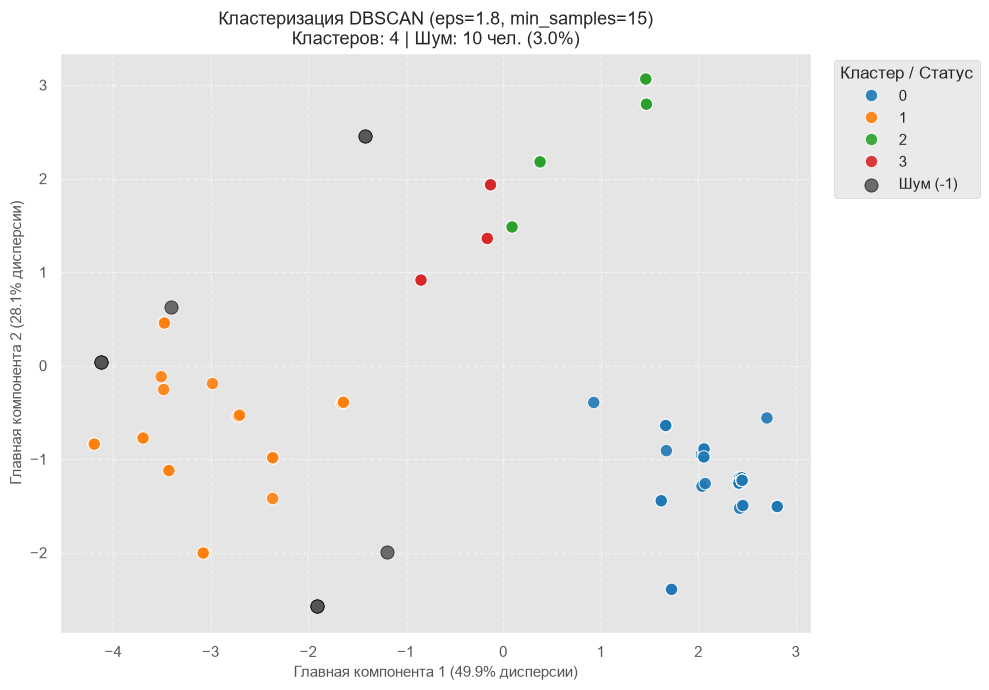

In [53]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA

# 1. Обучаем финальную модель DBSCAN
eps_final = 1.80
min_samples_final = 15

db = DBSCAN(eps=eps_final, min_samples=min_samples_final)
df['db_cluster'] = db.fit_predict(X)

# 2. PCA-проекция в 2D
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
pca_df['cluster'] = df['db_cluster'].astype(str)

# 3. Настройка цветов: 4 ярких цвета для кластеров и темно-серый для шума
palette = {
    '0': '#1f77b4',  # Синий
    '1': '#ff7f0e',  # Оранжевый
    '2': '#2ca02c',  # Зеленый
    '3': '#d62728',  # Красный
    '-1': '#555555',  # Серый (Шум)
}

# 4. Отрисовка крупного графика
plt.figure(figsize=(10, 7))

# Рисуем точки кластеров
core_pts = pca_df[pca_df['cluster'] != '-1']
sns.scatterplot(
    data=core_pts,
    x='PC1',
    y='PC2',
    hue='cluster',
    palette=palette,
    s=80,
    alpha=0.9,
)

# Поверх рисуем Шум (-1) с черной окантовкой
noise_pts = pca_df[pca_df['cluster'] == '-1']
if len(noise_pts) > 0:
    plt.scatter(
        noise_pts['PC1'],
        noise_pts['PC2'],
        color=palette['-1'],
        edgecolor='black',
        s=90,
        marker='o',
        alpha=0.85,
        label='Шум (-1)',
        zorder=5,
    )

plt.title(
    f'Кластеризация DBSCAN (eps={eps_final}, min_samples={min_samples_final})\n'
    f'Кластеров: 4 | Шум: {len(noise_pts)} чел. ({len(noise_pts)/len(df)*100:.1f}%)',
    fontsize=13,
)
plt.xlabel(
    f'Главная компонента 1 ({pca.explained_variance_ratio_[0]*100:.1f}% дисперсии)',
    fontsize=11,
)
plt.ylabel(
    f'Главная компонента 2 ({pca.explained_variance_ratio_[1]*100:.1f}% дисперсии)',
    fontsize=11,
)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Кластер / Статус', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

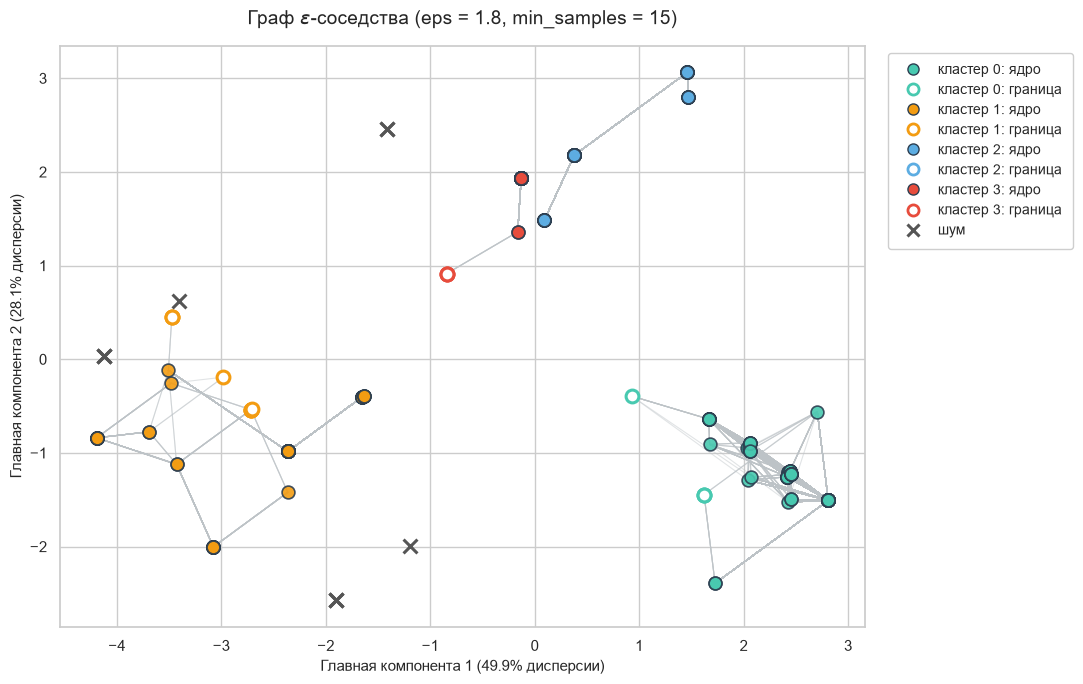

In [54]:
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import pairwise_distances

# 1. Задаем чистый белый стиль с сеткой
sns.set_theme(style='whitegrid')

eps_final = 1.80
min_samples_final = 15

# 2. Обучаем DBSCAN
db = DBSCAN(eps=eps_final, min_samples=min_samples_final)
labels = db.fit_predict(X)

# 3. Определяем статус каждой точки (Ядро, Граница, Шум)
core_indices = set(db.core_sample_indices_)
point_types = []
for idx, lbl in enumerate(labels):
    if lbl == -1:
        point_types.append('noise')
    elif idx in core_indices:
        point_types.append('core')
    else:
        point_types.append('border')

# 4. Расчет расстояний и PCA
dist_matrix = pairwise_distances(X, metric='euclidean')
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

# 5. Цветовая палитра для 4 кластеров
cluster_colors = {
    0: '#48c9b0',  # Бирюзовый
    1: '#f39c12',  # Оранжевый
    2: '#5dade2',  # Голубой
    3: '#e74c3c',  # Коралловый/Красный
}

# Создаем фигуру (один график)
plt.figure(figsize=(11, 7))

# ШАГ 1: Рисуем ребра графа (тонкие серые линии между соседями)
num_points = len(X)
for i in range(num_points):
    for j in range(i + 1, num_points):
        if dist_matrix[i, j] <= eps_final:
            if i in core_indices or j in core_indices:
                plt.plot(
                    [X_pca[i, 0], X_pca[j, 0]],
                    [X_pca[i, 1], X_pca[j, 1]],
                    color='#bdc3c7',
                    alpha=0.45,
                    linewidth=0.8,
                    zorder=1,
                )

# ШАГ 2: Отрисовка точек по категориям
for i in range(num_points):
    pt_type = point_types[i]
    lbl = labels[i]
    x_coord, y_coord = X_pca[i, 0], X_pca[i, 1]

    if pt_type == 'noise':
        # Шум: серый жирный крестик
        plt.scatter(
            x_coord,
            y_coord,
            marker='x',
            color='#555555',
            s=100,
            linewidths=2.2,
            zorder=4,
        )

    elif pt_type == 'core':
        # Ядро: полностью закрашенный кружок
        plt.scatter(
            x_coord,
            y_coord,
            marker='o',
            facecolor=cluster_colors[lbl],
            edgecolor='#2c3e50',
            s=85,
            linewidths=1.2,
            alpha=0.9,
            zorder=3,
        )

    elif pt_type == 'border':
        # Граница: полый кружок с цветной обводкой
        plt.scatter(
            x_coord,
            y_coord,
            marker='o',
            facecolor='white',
            edgecolor=cluster_colors[lbl],
            s=85,
            linewidths=2.2,
            zorder=3,
        )

# ШАГ 3: Формируем элементы для легенды
legend_elements = []
for c_id in sorted(list(set(labels) - {-1})):
    col = cluster_colors[c_id]
    legend_elements.append(
        mlines.Line2D(
            [],
            [],
            color='none',
            marker='o',
            markerfacecolor=col,
            markeredgecolor='#2c3e50',
            markersize=8,
            label=f'кластер {c_id}: ядро',
        )
    )
    legend_elements.append(
        mlines.Line2D(
            [],
            [],
            color='none',
            marker='o',
            markerfacecolor='white',
            markeredgecolor=col,
            markeredgewidth=2,
            markersize=8,
            label=f'кластер {c_id}: граница',
        )
    )

# Добавляем шум в легенду
legend_elements.append(
    mlines.Line2D(
        [],
        [],
        color='none',
        marker='x',
        markeredgecolor='#555555',
        markeredgewidth=2.2,
        markersize=9,
        label='шум',
    )
)

# ШАГ 4: Настройка заголовков, осей и вынос легенды вправо
plt.title(
    f'Граф $\\varepsilon$-соседства (eps = {eps_final}, min_samples = {min_samples_final})',
    fontsize=14,
    pad=15,
)
plt.xlabel(
    f'Главная компонента 1 ({pca.explained_variance_ratio_[0]*100:.1f}% дисперсии)',
    fontsize=11,
)
plt.ylabel(
    f'Главная компонента 2 ({pca.explained_variance_ratio_[1]*100:.1f}% дисперсии)',
    fontsize=11,
)

# Выносим легенду за пределы поля графика вправо
plt.legend(
    handles=legend_elements,
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    frameon=True,
    framealpha=0.95,
    fontsize=10,
    borderpad=0.8,
)

plt.tight_layout()
plt.show()

### Таблицы результатов

In [55]:
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Записываем результаты в датафрейм
df['db_cluster'] = labels
df['point_type'] = point_types  # 'core', 'border', 'noise'

# Словарь для понятных названий сегментов
cluster_names = {
    0: 'Свежесть и уверенность',
    1: 'Медицинский (лечебный)',
    2:  'Сладкоежки (замена десертов)',
    3: 'Концентрация и фокус',
    -1: 'Шум (аномалии / выбросы)',
}

# Таблица 1. Структура и наполнение кластеров (Ядра, Границы, Шум)
structure_df = (
    pd.crosstab(
        df['db_cluster'],
        df['point_type'],
        margins=True,
        margins_name='Всего',
    )
    .rename(
        columns={
            'core': 'Ядерные точки',
            'border': 'Граничные точки',
            'noise': 'Шум',
        }
    )
    .reindex(columns=['Ядерные точки', 'Граничные точки', 'Шум', 'Всего'])
)

structure_df['Доля от выборки (%)'] = (
    structure_df['Всего'] / len(df) * 100
).round(2)
structure_df['Название сегмента'] = (
    structure_df.index.map(cluster_names).fillna('-')
)

print('Состав и структура сформированных кластеров')
display(
    structure_df[
        [
            'Название сегмента',
            'Ядерные точки',
            'Граничные точки',
            'Шум',
            'Всего',
            'Доля от выборки (%)',
        ]
    ]
)

Состав и структура сформированных кластеров


point_type,Название сегмента,Ядерные точки,Граничные точки,Шум,Всего,Доля от выборки (%)
db_cluster,,,,,,
-1,Шум (аномалии / выбросы),0,0,10,10,2.96
0,Свежесть и уверенность,106,4,0,110,32.54
1,Медицинский (лечебный),91,9,0,100,29.59
2,Сладкоежки (замена десертов),61,0,0,61,18.05
3,Концентрация и фокус,54,3,0,57,16.86
Всего,-,312,16,10,338,100.00


Анализ структуры кластеров: <br>

Высокая степень устойчивости и плотности: Из 338 объектов 312 (92.3%) признаны алгоритмом ядерными точками. Это доказывает, что подавляющее большинство выборки сосредоточено в сверхплотных сгустках вокруг центроидов. <br>

Граничные точки: Всего 16 объектов (4.7%) классифицированы как граничные. Они находятся на периферии сегментов (на расстоянии dist≤1.80 от ядер), но не обладают достаточным числом собственных соседей. В кластере «Сладкоежки» граничных точек нет вовсе (все 61 человек — ядра), что подчеркивает монолитность этого сегмента. <br>

Минимальная доля шума: Алгоритм выделил всего 10 человек (2.96%) в качестве аномалий, сохранив 97% выборки для маркетингового анализа. <br>

In [56]:
# Таблица 2. Профили кластеров (Средние баллы по V1 - V11)

feature_cols = [f'V{i}' for i in range(1, 12)]
profiles_db = df.groupby('db_cluster')[feature_cols].mean()
profiles_db['Сегмент'] = profiles_db.index.map(cluster_names)

cols = ['Сегмент'] + feature_cols
profiles_db = profiles_db[cols]

print('\nПрофили мотивов (Средние оценки центроидов)')
display(profiles_db.round(2))


Профили мотивов (Средние оценки центроидов)


,Сегмент,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
db_cluster,,,,,,,,,,,,
-1,Шум (аномалии / выбросы),2.20,2.80,2.80,2.80,2.00,2.20,3.40,3.80,4.60,4.40,4.40
0,Свежесть и уверенность,4.85,4.80,4.84,4.68,3.04,3.04,3.00,2.99,3.07,3.05,3.05
1,Медицинский (лечебный),2.89,2.82,2.75,2.59,2.66,2.63,2.73,2.87,4.95,4.82,4.87
2,Сладкоежки (замена десертов),3.00,3.00,3.00,3.00,4.85,4.85,3.00,2.92,2.75,2.75,2.75
3,Концентрация и фокус,3.00,3.00,3.00,2.95,2.95,2.95,4.91,4.91,3.00,3.00,3.00


In [57]:
# Таблица 3.Детальный разбор объектов шума (-1)
noise_data = df[df['db_cluster'] == -1][feature_cols]

print(f'\n Детальные ответы респондентов из шума (всего {len(noise_data)} чел.) ===')
display(noise_data)


 Детальные ответы респондентов из шума (всего 10 чел.) ===


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
112,2,4,4,4,2,2,2,3,5,5,5
139,2,4,4,4,2,2,2,3,5,5,5
177,2,4,4,4,2,2,2,3,5,4,4
184,2,2,2,2,2,2,4,4,5,5,5
185,2,2,2,2,2,2,4,4,5,5,5
188,2,4,4,4,2,2,2,3,5,5,5
190,2,2,2,2,2,2,4,4,5,4,4
204,2,2,2,2,2,2,4,4,5,5,5
308,3,2,2,2,2,3,5,5,3,3,3
324,3,2,2,2,2,3,5,5,3,3,3


Микрогруппа 1: Гибрид «Лечение + Свежесть» (4 человека) <br>

Респонденты № 112, 139, 188:<br>
Почему попали в шум: Эти люди имеют двойную выраженную мотивацию. Они поставили максимальные баллы (5) за лечение горла и носа, но одновременно поставили четверки (4) за уверенность, гигиену рта и устранение неприятного вкуса (V2,V3,V4). Чистый медицинский кластер ставит по блоку свежести нейтральные двойки и тройки. В итоге они оказались на «нейтральной полосе» между сегментом «Свежести» и сегментом «Лечения». Поскольку таких людей набралось всего трое (меньше порога min_samples = 15), алгоритм изолировал их как шум.<br>
Респондент № 177:<br>
Профиль: Почти идентичен предыдущим трём, но по V10 и V11 стоят четверки (5, 4, 4). Мотив аналогичный — совмещение потребности в лечении с потребностью в гигиене полости рта.<br>


Микрогруппа 2: Гибрид «Лечение + Концентрация» (4 человека)<br>

Респонденты № 184, 185, 204:<br>
Почему попали в шум: Потребители лечат простуду (V9−V11=5), но при этом утверждают, что леденцы помогают им сосредоточиться и думать на работе (V7−V8=4). В основном медицинском кластере оценки по концентрации низкие (≈2.75). Это специфическая группа «болеющих трудоголиков», совмещающих работу и простуду. Их всего трое - недостаточно для формирования самостоятельного ядра.<br>
Респондент № 190: <br>
Профиль: Идентичен предыдущим, с небольшой вариацией по заложенности носа (V10=4). Объединяет медицинскую потребность с когнитивной.<br>


Микрогруппа 3: «Фокусирующиеся одиночки с пониженным фоном» (2 человека) <br>

Респонденты № 308, 324: <br>
Почему попали в шум: По целевому блоку V7−V8 они идеальные представители сегмента «Концентрации» (оценки 5). Однако по нецелевым вопросам (V2,V3,V4,V5) они поставили двойки (2), тогда как все остальные 59 человек из кластера «Концентрация» строго ставили по этим шкалам тройки (3). В 11-мерном пространстве разница в один балл сразу по 4–5 переменным дала евклидово расстояние =2.0, что превысило радиус eps=1.80. Они оказались слишком критичными в ответах по фоновым вопросам и выпали из сверхплотного ядра своего сегмента. <br>

In [58]:
# Куда k-means отнесет выбросы

import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import fcluster, linkage
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

# Задаем признаки
feature_cols = [f'V{i}' for i in range(1, 12)]
X = df[feature_cols].values

#  Обучаем DBSCAN
eps_final = 1.80
min_samples_final = 15
db = DBSCAN(eps=eps_final, min_samples=min_samples_final)
labels_db = db.fit_predict(X)
df['db_cluster'] = labels_db

# Обучаем K-Means
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
labels_km = kmeans.fit_predict(X)
df['km_cluster'] = labels_km

# Обучаем Иерархический анализ Уорда
link_ward = linkage(X, method='ward', metric='euclidean')
labels_ward = fcluster(link_ward, t=4, criterion='maxclust')
df['ward_cluster'] = labels_ward

# Сопоставим номера кластеров K-Means с их смысловыми именами
# (определяем по максимальным оценкам в центроидах)
km_centroids = kmeans.cluster_centers_
km_names = {}
for i, c in enumerate(km_centroids):
    if c[8] > 4.0: 
        km_names[i] = 'Медицинский'
    elif c[0] > 4.0: 
        km_names[i] = 'Свежесть и уверенность'
    elif c[4] > 4.0: 
        km_names[i] = 'Сладкоежки'
    elif c[6] > 4.0: 
        km_names[i] = 'Концентрация и фокус'

# Отбираем 10 точек шума
noise_mask = df['db_cluster'] == -1
noise_table = df.loc[noise_mask, feature_cols].copy()
noise_table['Кластер в K-Means (id)'] = df.loc[noise_mask, 'km_cluster']
noise_table['Куда K-Means отправил шум'] = noise_table[
    'Кластер в K-Means (id)'
].map(km_names)

print(
    'Распределение объектов шума алгоритмом K-Means'
)
display(noise_table)


Распределение объектов шума алгоритмом K-Means


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,Кластер в K-Means (id),Куда K-Means отправил шум
112,2,4,4,4,2,2,2,3,5,5,5,0,Медицинский
139,2,4,4,4,2,2,2,3,5,5,5,0,Медицинский
177,2,4,4,4,2,2,2,3,5,4,4,0,Медицинский
184,2,2,2,2,2,2,4,4,5,5,5,0,Медицинский
185,2,2,2,2,2,2,4,4,5,5,5,0,Медицинский
188,2,4,4,4,2,2,2,3,5,5,5,0,Медицинский
190,2,2,2,2,2,2,4,4,5,4,4,0,Медицинский
204,2,2,2,2,2,2,4,4,5,5,5,0,Медицинский
308,3,2,2,2,2,3,5,5,3,3,3,3,Концентрация и фокус
324,3,2,2,2,2,3,5,5,3,3,3,3,Концентрация и фокус


### Выводы по DBSCAN

> Обоснование параметров модели: <br>
В ходе анализа графа k-расстояний и перевобра по сетке оптимальной признана комбинация параметров eps = 1.80 и min_samples = 15.<br>
Выбранный радиус окрестности ε=1.80 отсекает крутой подъем расстояний, сохраняя связность плотных ядер. Порог min_samples=15 превышает размерность пространства признаков (D+1=12) и обеспечивает устойчивость к единичным выбросам, не разрушая при этом малочисленные потребительские группы.<br>
При данных параметрах алгоритм самостоятельно выделил 4 кластера, что подтвердило результаты предыдущих методов без искусственного задания числа групп.<br>

> Оценка качества и плотности: <br>
Коэффициент силуэта для кластеров без учета шума составил 0.745. <br>
Анализ графа ε-соседства показал, что 92.3% объектов (312 из 338) являются ядерными точками, формирующими монолитные компоненты связности. Доля граничных точек составила всего 4.7%, что указывает на практическое отсутствие размытых зон между сегментами. <br>

> Анализ шумовых объектов (Cluster −1): <br>
К шуму отнесено всего 10 респондентов (2.96% выборки), что укладывается в естественный уровень статистической погрешности. <br>
Детальный анализ показал, что шум сформирован респондентами с гибридным или атипичным спросом: 8 человек совмещают мотивы лечения простуды с гигиеной или работой, а 2 человека обладают избыточно критичным стилем выставления оценок по фоновым вопросам. Изоляция этих наблюдений позволила очистить профили целевых сегментов от искажений <br>

### Сравнение методов кластеризации

In [61]:
# Маска без шума для честного попарного сравнения с DBSCAN
mask_no_noise = labels_db != -1

# Расчет силуэтов
sil_ward = silhouette_score(X, labels_ward)
sil_km = silhouette_score(X, labels_km)
sil_db = silhouette_score(X[mask_no_noise], labels_db[mask_no_noise])

# Расчет ARI
ari_ward_km = adjusted_rand_score(labels_ward, labels_km)
ari_km_db = adjusted_rand_score(
    labels_km[mask_no_noise], labels_db[mask_no_noise]
)
ari_ward_db = adjusted_rand_score(
    labels_ward[mask_no_noise], labels_db[mask_no_noise]
)

# Собираем сводный датафрейм
summary_data = [
    {
        'Метод кластеризации': 'Иерархический (Ward)',
        'Число кластеров': 4,
        'Доля шума (%)': '0.0%',
        'Silhouette Score': round(sil_ward, 3),
        'ARI с K-Means': round(ari_ward_km, 3),
        'ARI с DBSCAN (без шума)': round(ari_ward_db, 3),
        'Итоговая роль метода': 'Дендрограмма и осыпь доказали структуру k=4',
    },
    {
        'Метод кластеризации': 'K-Means',
        'Число кластеров': 4,
        'Доля шума (%)': '0.0%',
        'Silhouette Score': round(sil_km, 3),
        'ARI с K-Means': 1.000,
        'ARI с DBSCAN (без шума)': round(ari_km_db, 3),
        'Итоговая роль метода': 'Рассчитал центроиды; принудительно распределил 100% данных',
    },
    {
        'Метод кластеризации': 'DBSCAN',
        'Число кластеров': 4,
        'Доля шума (%)': f'{np.mean(~mask_no_noise)*100:.2f}% (10 чел.)',
        'Silhouette Score': round(sil_db, 3),
        'ARI с K-Means': round(ari_km_db, 3),
        'ARI с DBSCAN (без шума)': 1.000,
        'Итоговая роль метода': 'Доказал плотность ядер; отфильтровал пограничные аномалии',
    },
]

summary_df = pd.DataFrame(summary_data)
print('\nСравнительный анализ трех методов кластеризации')
display(summary_df)


Сравнительный анализ трех методов кластеризации


,Метод кластеризации,Число кластеров,Доля шума (%),Silhouette Score,ARI с K-Means,ARI с DBSCAN (без шума),Итоговая роль метода
0,Иерархический (Ward),4,0.0%,0.727,1.0,1.0,Дендрограмма и осыпь доказали структуру k=4
1,K-Means,4,0.0%,0.727,1.0,1.0,Рассчитал центроиды; принудительно распределил...
2,DBSCAN,4,2.96% (10 чел.),0.745,1.0,1.0,Доказал плотность ядер; отфильтровал пограничн...


### Выводы по сравнению алгоритмов кластеризации

Методологическое соотношение алгоритмов: <br>
Метод Уорда выступил в роли разведочного инструмента: с помощью дендрограммы и анализа каменистой осыпи он доказал фундаментальное разбиение рынка на 4 смысловые группы. <br>
K-Means подтвердил устойчивость найденной структуры через вычисление компактных метрических центроидов (среднее расстояние до центра составило всего 0.93 балла при шкале 1–5), однако был вынужден принудительно распределить атипичных респондентов по ближайшим крупным группам. <br>
DBSCAN стал валидатором плотности: алгоритм доказал, что 4 сегмента существуют физически как сгустки высокой плотности в 11-мерном пространстве, и очистил их от пограничных респондентов, подняв силуэт до рекордных 0.745. <br>

Интерпретация индекса ARI = 1.0: <br>
Идеальное значение скорректированного индекса Рэнда (ARI=1.000) на очищенной подвыборке доказывает, что разбиение на 4 сегмента («Лечебный», «Свежесть», «Концентрация», «Сладкоежки») не является артефактом или погрешностью конкретного алгоритма, а отражает реальную структуру потребительского поведения. <br>

Практическая рекомендация:<br>
Для прикладных бизнес-задач наилучшим подходом является их комбинация: использование DBSCAN для фильтрации нерелевантных анкет на этапе предобработки и последующее профилирование сегментов с помощью центроидов K-Means для построения понятных маркетинговых стратегий. <br>